# 🦜🕸️ LangGraph Fundamentals: Nodes, Edges & State

Welcome! This notebook teaches the three core building blocks of LangGraph through a **simple, end-to-end example**: a three-step text-processing pipeline.

| Concept | What it is | Analogy |
|---------|-----------|---------|
| **State** | A shared data container passed between steps | A whiteboard everyone reads & writes |
| **Node** | A function that reads State, does work, and returns updates | A worker at a station |
| **Edge** | A connection that decides which node runs next | A conveyor belt between stations |

> **Goal:** by the end you'll be able to build your own multi-step LangGraph workflow from scratch.

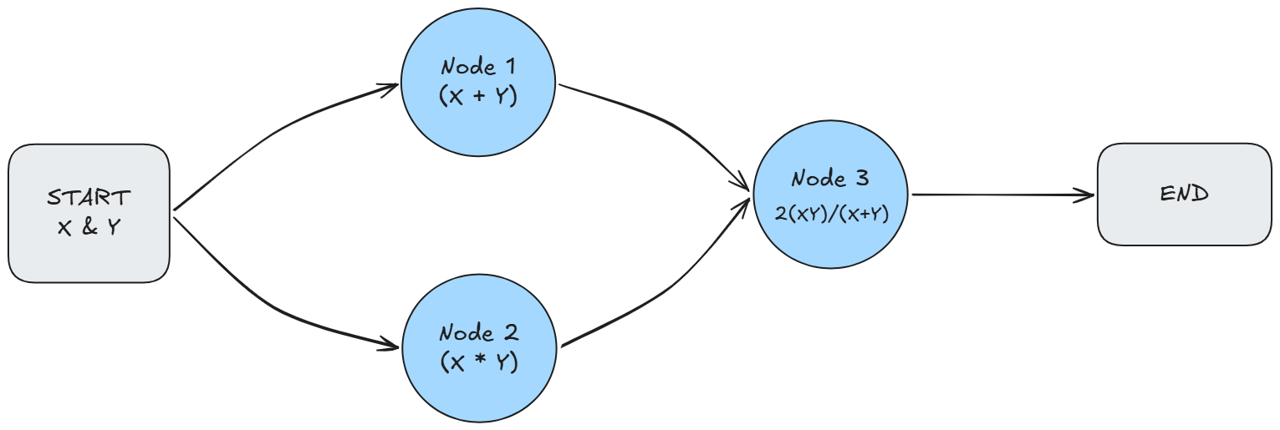

In [1]:
from IPython.display import Image, display
display(Image("images/1.png"))

<h3><center>  <div style="background-color:lightpink;border-radius:10px; padding: 10px;">Setup ⚙️</div></center></h3>

In [8]:
# Installing langgraph
%pip install -qU langgraph


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


<h3><center>  <div style="background-color:skyblue;border-radius:10px; padding: 10px;">Langgraph Basics</div></center></h3>

In [9]:
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END


#### 1. Define the State 🗂️

**State** is the single source of truth for your workflow. Every node receives the current State and can return a partial update — LangGraph merges the update automatically.

```
State = { key: value, key: value, ... }
```

Think of it as a shared dictionary where each node can read from and write to!

In [10]:
class State(BaseModel):
    """
    Our shared state carries following fields — each step adds one.

    x, y : input from user
    summation : x+y
    multiplication : x * y
    harmonic_mean : 2(multiplication)/summation
    """
    x: int
    y: int
    summation: int = 0
    multiplication: int = 0
    harmonic_mean: float = 0.0

# Peek at the structure
print("State keys:", list(State.model_fields.keys()))


State keys: ['x', 'y', 'summation', 'multiplication', 'harmonic_mean']


#### 2. Define the Nodes

Each **node** is a plain Python function with the signature:

```python
def my_node(state: MyState) -> dict:
    # read from state
    # do some work
    return {"key": new_value}   # ← partial update merged into State
```

In [11]:
# Node 1
def summation_node(state: State) -> dict:
    """Step 1 : Summation step i.e. x + y"""
    total = state.x + state.y
    print(f"The summation is {total}")
    return {"summation": total}


# Node 2
def multiplication_node(state: State) -> dict:
    """Step 2 : Multiplication step i.e. x * y"""
    product = state.x * state.y
    print(f"The multiplication is {product}")
    return {"multiplication": product}


# Node 3
def harmonic_mean_node(state: State) -> dict:
    """Step 3 : Harmonic mean step i.e. 2(x * y)/(x + y)"""
    answer = 2 * state.multiplication / state.summation
    print(f"The harmonic_mean is {answer}")
    return {"harmonic_mean": answer}


#### 3. Define the Edges and Build the Graph 🔗

**Edges** connect nodes and tell LangGraph what to run next.

We also need to tell the graph:
- where to **start** (`add_edge(START, ...)`)
- where to **finish** (`add_edge(..., END)`)

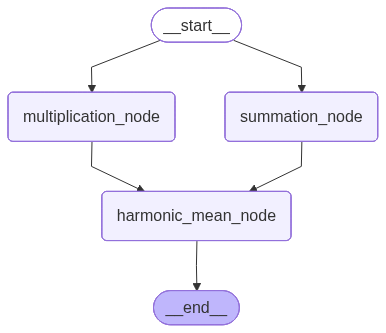

In [12]:
# 1. Create a StateGraph and tell it which State class to use
workflow = StateGraph(State)

# 2. Register each node (name → function)
workflow.add_node("summation_node", summation_node)
workflow.add_node("multiplication_node", multiplication_node)
workflow.add_node("harmonic_mean_node", harmonic_mean_node)

# 3. Wire the edges
workflow.add_edge(START, "summation_node")
workflow.add_edge(START, "multiplication_node")
workflow.add_edge("multiplication_node", "harmonic_mean_node")
workflow.add_edge("summation_node", "harmonic_mean_node")
workflow.add_edge("harmonic_mean_node", END)

# 4. Compile — this validates the graph and produces a runnable object
graph = workflow.compile()

# Let's see the graph
graph

#### 4. Run the Graph ▶️

Call `graph.invoke(initial_state)` to execute the full pipeline. LangGraph will:
1. Start with the initial state
2. Merge each node's returned dict back into State
3. Follow the edges until it reaches `END`
4. Return the **final, fully-updated State**


In [13]:
output = graph.invoke({"x":3, "y":4})

The multiplication is 12
The summation is 7
The harmonic_mean is 3.4285714285714284


In [15]:
# Checking the output
output

{'x': 3,
 'y': 4,
 'summation': 7,
 'multiplication': 12,
 'harmonic_mean': 3.4285714285714284}

#### Summary 📝

| Concept | Key API | Role |
|---------|---------|------|
| **State** | `BaseModel` | Shared data container for the whole run |
| **Node** | `workflow.add_node(name, fn)` | Function that reads State and returns partial updates |
| **Edge** | `workflow.add_edge(a, b)` | Defines execution order between nodes |
| **Entry point** | `add_edge(START, name)` | Start point of the workflow|
| **Termination** | `add_edge(name, END)` | Signals the graph is done |
| **Invoke** | `graph.invoke(state)` | Runs the full graph, returns final State |
